# Lab 9

Find the best set of hyperparameters (n_neighbors and metric) of k-NN model for classification of the iris dataset (attached), with respect to the target variable "variety". 

- k search space: Use odd k values in [1,7].

- metric search space: three distance metrics of your choice.

## Import Libraries



In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

## Get the Data(Iris dataset)



In [2]:
df = pd.read_csv('/Users/patriciasiuhaliu/Documents/Semester 2/python/week 10/Lab/iris-KNN.csv')
print(df.head())
df['variety'].unique()

   sepal.length  sepal.width  petal.length  petal.width  variety
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0


array([0, 1])

## Standardize the Variables



## Train Test Split

In [3]:
from sklearn.model_selection import train_test_split
y=df['variety']
x=df.drop('variety',axis=1)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=101)
print(x_train.shape,x_test.shape,x.shape)
print(y_train.shape,y_test.shape,y.shape)

(80, 4) (20, 4) (100, 4)
(80,) (20,) (100,)


## Standardize the Variables

In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)
print(x_train)
print(x_test)


[[ 0.64246942 -0.18172726  0.85590189  1.1935046 ]
 [-1.41343272  0.24586629 -1.08460442 -1.0923974 ]
 [ 1.59134733 -0.60932081  1.13311708  1.1935046 ]
 [-0.93899377 -1.46450792  0.23216772  0.31431153]
 [-1.2552864   0.24586629 -1.15390822 -1.0923974 ]
 [-1.88787168 -0.18172726 -1.29251582 -1.26823601]
 [ 0.80061574 -0.39552404  1.06381329  1.1935046 ]
 [ 1.74949365 -0.39552404  1.13311708  0.84182737]
 [-0.14826217 -0.18172726  1.06381329  1.1935046 ]
 [ 0.95876206 -0.18172726  1.13311708  1.01766599]
 [ 1.90763997  0.03206952  1.20242088  1.1935046 ]
 [ 0.4843231   1.95624051 -1.22321202 -1.0923974 ]
 [-0.62270113  0.45966307 -0.87669303 -0.56488155]
 [-0.78084745  0.67345985 -0.94599683 -0.74072017]
 [-1.41343272  1.1010534  -1.36181961 -1.0923974 ]
 [ 0.95876206 -0.60932081  0.7172943   0.84182737]
 [-0.46455481  0.88725662 -1.01530063 -1.0923974 ]
 [-0.14826217  0.67345985 -0.87669303 -1.0923974 ]
 [ 1.90763997  0.03206952  0.99450949  1.01766599]
 [-1.09714009  0.03206952 -0.94

# Euclidean

## Models



In [5]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=7, metric='euclidean')
knn.fit(x_train,y_train)
pred = knn.predict(x_test)
print(pred)

[0 0 0 1 1 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0]


## Predictions and Evaluations



In [6]:
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[12  0]
 [ 1  7]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       1.00      0.88      0.93         8

    accuracy                           0.95        20
   macro avg       0.96      0.94      0.95        20
weighted avg       0.95      0.95      0.95        20



## Choosing best hyperparameters



In [7]:
from sklearn import metrics
error_rate = []
acc = []
for i in range(1,8):   
    knn = KNeighborsClassifier(n_neighbors=i, metric='euclidean')
    knn.fit(x_train,y_train)
    pred_i = knn.predict(x_test)
    error_rate.append(np.mean(pred_i != y_test))
    acc.append(metrics.accuracy_score(y_test, pred_i))

Text(0, 0.5, 'Error Rate')

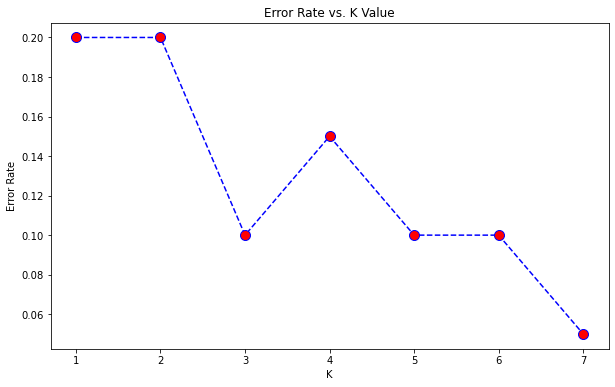

In [8]:
plt.figure(figsize=(10,6))
plt.plot(range(1,8),error_rate,color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

Maximum accuracy:- 0.95 at K = 7


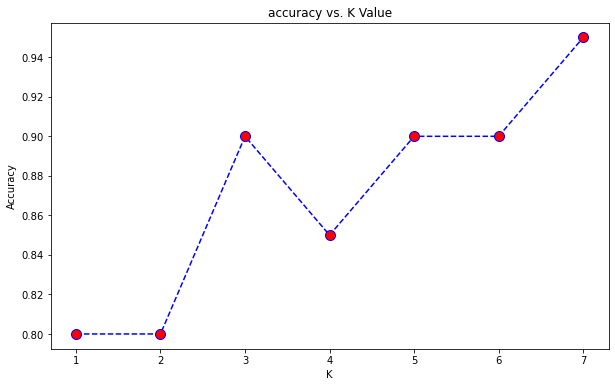

In [9]:
plt.figure(figsize=(10,6))
plt.plot(range(1,8),acc,color = 'blue',linestyle='dashed', 
         marker='o',markerfacecolor='red', markersize=10)
plt.title('accuracy vs. K Value')
plt.xlabel('K')
plt.ylabel('Accuracy')
print("Maximum accuracy:-",max(acc),"at K =",acc.index(max(acc))+1)


## We got the max accuracy of 0.95 at K=7. As we
## already derived the error plot and got the 
## minimum error at k=7, so we can 
## consider better efficiency at K = 7 value.

# Manhattan

## Model

In [10]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=7, metric='manhattan')
knn.fit(x_train,y_train)
pred = knn.predict(x_test)
print(pred)

[0 0 0 1 1 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0]


## Predictions and Evaluations

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[12  0]
 [ 1  7]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       1.00      0.88      0.93         8

    accuracy                           0.95        20
   macro avg       0.96      0.94      0.95        20
weighted avg       0.95      0.95      0.95        20



## Choosing best hyperparameters

In [12]:
from sklearn import metrics
error_rate = []
acc = []
for i in range(1,8):   
    knn = KNeighborsClassifier(n_neighbors=i, metric='manhattan')
    knn.fit(x_train,y_train)
    pred_i = knn.predict(x_test)
    error_rate.append(np.mean(pred_i != y_test))
    acc.append(metrics.accuracy_score(y_test, pred_i))

Text(0, 0.5, 'Error Rate')

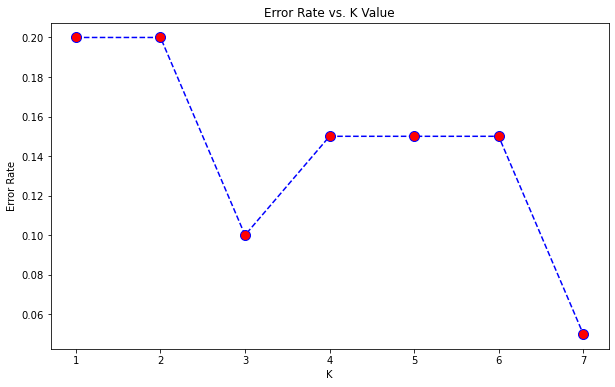

In [13]:
plt.figure(figsize=(10,6))
plt.plot(range(1,8),error_rate,color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

Maximum accuracy:- 0.95 at K = 7


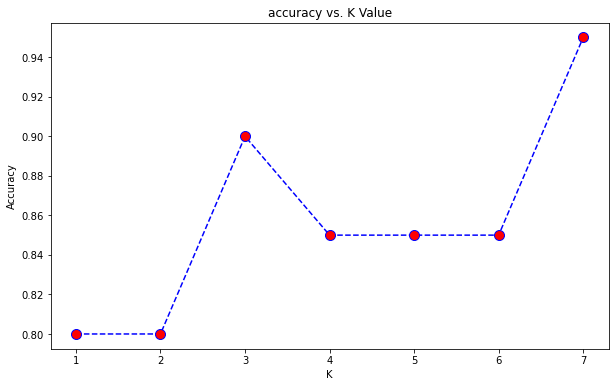

In [14]:
plt.figure(figsize=(10,6))
plt.plot(range(1,8),acc,color = 'blue',linestyle='dashed', 
         marker='o',markerfacecolor='red', markersize=10)
plt.title('accuracy vs. K Value')
plt.xlabel('K')
plt.ylabel('Accuracy')
print("Maximum accuracy:-",max(acc),"at K =",acc.index(max(acc))+1)

## We got the max accuracy of 0.95 at K=7. As we
## already derived the error plot and got the
## minimum error at k=7, so we can
## consider better efficiency at K = 7 value.

# Chebyshev

## Model

In [15]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5, metric='chebyshev')
knn.fit(x_train,y_train)
pred = knn.predict(x_test)
print(pred)

[0 0 0 1 1 0 1 1 0 1 1 0 0 1 0 0 1 0 0 0]


## Predictions and Evaluations

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[11  1]
 [ 1  7]]
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        12
           1       0.88      0.88      0.88         8

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20



## Choosing best hyperparameters

In [17]:
from sklearn import metrics
error_rate = []
acc = []
for i in range(1,8):   
    knn = KNeighborsClassifier(n_neighbors=i, metric='chebyshev')
    knn.fit(x_train,y_train)
    pred_i = knn.predict(x_test)
    error_rate.append(np.mean(pred_i != y_test))
    acc.append(metrics.accuracy_score(y_test, pred_i))

Text(0, 0.5, 'Error Rate')

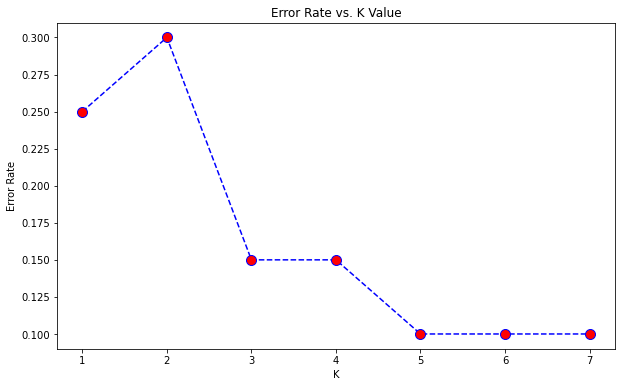

In [18]:
plt.figure(figsize=(10,6))
plt.plot(range(1,8),error_rate,color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

Maximum accuracy:- 0.9 at K = 5


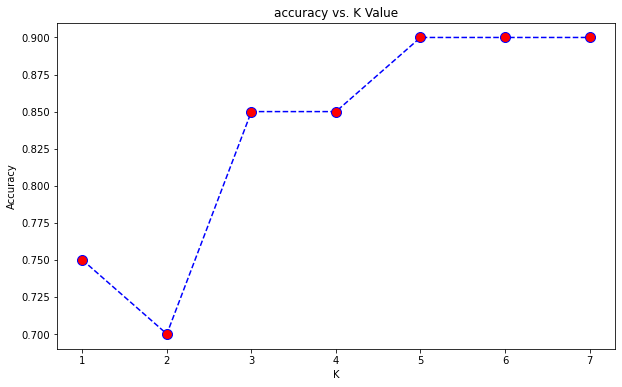

In [19]:
plt.figure(figsize=(10,6))
plt.plot(range(1,8),acc,color = 'blue',linestyle='dashed', 
         marker='o',markerfacecolor='red', markersize=10)
plt.title('accuracy vs. K Value')
plt.xlabel('K')
plt.ylabel('Accuracy')
print("Maximum accuracy:-",max(acc),"at K =",acc.index(max(acc))+1)

## We got the max accuracy of 0.9 at K=5. As we
## already derived the error plot and got the
## minimum error at k=5, so we can
## consider better efficiency at K = 5 value.

# Conclusion

## Since we got  maximum accuracy of 0.95 at K=7 & minimum error at k=7 for euclidean and manhattan, we can take any of the two as a good model